In [34]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("building_health_monitoring_dataset.csv")

df.head()

,Timestamp,Accel_X (m/s^2),Accel_Y (m/s^2),Accel_Z (m/s^2),Strain (με),Temp (°C),Condition Label
0,2025-04-19 00:00:00,0.149014,0.419807,9.742482,61.843849,23.704760,0
1,2025-04-19 00:00:01,-0.041479,0.277390,9.795548,82.792300,24.953195,0
2,2025-04-19 00:00:02,0.194307,0.017889,9.730758,91.727889,25.027025,0
3,2025-04-19 00:00:03,0.456909,-0.194081,9.779204,137.753753,25.708946,0
4,2025-04-19 00:00:04,-0.070246,0.209467,9.620639,111.131062,22.949712,0


In [9]:
df.shape

(1000, 7)

In [6]:
df.describe()

,Accel_X (m/s^2),Accel_Y (m/s^2),Accel_Z (m/s^2),Strain (με),Temp (°C),Condition Label
count,980.000000,980.000000,980.000000,980.000000,980.000000,1000.000000
mean,0.100986,0.018795,9.811055,111.858121,25.029765,0.409000
std,0.340176,0.297789,0.098196,28.689447,1.521938,0.684242
min,-0.795291,-0.882117,9.508049,41.860236,20.244361,0.000000
25%,-0.144132,-0.182874,9.746165,92.125805,24.036035,0.000000
50%,0.079727,0.016289,9.809975,109.018287,25.059944,0.000000
75%,0.306407,0.217719,9.876602,128.718915,26.045197,1.000000
max,1.337972,0.941325,10.202624,224.861859,29.838898,2.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Timestamp        1000 non-null   object 
 1   Accel_X (m/s^2)  980 non-null    float64
 2   Accel_Y (m/s^2)  980 non-null    float64
 3   Accel_Z (m/s^2)  980 non-null    float64
 4   Strain (με)      980 non-null    float64
 5   Temp (°C)        980 non-null    float64
 6   Condition Label  1000 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 54.8+ KB


**Data Preprocessing**

In [10]:
df.isnull().sum()

Timestamp           0
Accel_X (m/s^2)    20
Accel_Y (m/s^2)    20
Accel_Z (m/s^2)    20
Strain (με)        20
Temp (°C)          20
Condition Label     0
dtype: int64

In [11]:
df[df.isnull().any(axis=1)].head(20)

,Timestamp,Accel_X (m/s^2),Accel_Y (m/s^2),Accel_Z (m/s^2),Strain (με),Temp (°C),Condition Label
23,2025-04-19 00:00:23,-0.427424,0.642681,9.679118,NaN,26.175384,0
42,2025-04-19 00:00:42,0.335433,0.323604,9.757591,148.269375,NaN,2
55,2025-04-19 00:00:55,NaN,-0.201487,9.728074,82.864558,25.309543,0
65,2025-04-19 00:01:05,0.570771,NaN,9.751724,136.431864,24.050680,1
71,2025-04-19 00:01:11,0.461411,0.143112,NaN,134.050293,23.942907,0
76,2025-04-19 00:01:16,0.248011,-0.466975,9.871577,145.503110,NaN,1
83,2025-04-19 00:01:23,-0.155481,NaN,9.580382,77.656271,22.132539,0
84,2025-04-19 00:01:24,0.094501,0.114581,9.754946,156.283085,NaN,2
88,2025-04-19 00:01:28,-0.158928,NaN,9.764675,60.977963,26.709333,0
122,2025-04-19 00:02:02,0.420838,NaN,9.808074,109.824153,NaN,0


In [12]:
df.isnull().sum(axis=1).value_counts().sort_index()

0    904
1     92
2      4
Name: count, dtype: int64

In [16]:
missing_rows = df[df.isnull().any(axis=1)]

missing_rows[["Timestamp"]].head(20)

,Timestamp
23,2025-04-19 00:00:23
42,2025-04-19 00:00:42
55,2025-04-19 00:00:55
65,2025-04-19 00:01:05
71,2025-04-19 00:01:11
76,2025-04-19 00:01:16
83,2025-04-19 00:01:23
84,2025-04-19 00:01:24
88,2025-04-19 00:01:28
122,2025-04-19 00:02:02


In [20]:
missing_rows[["Timestamp"]].tail(20)

,Timestamp
799,2025-04-19 00:13:19
811,2025-04-19 00:13:31
816,2025-04-19 00:13:36
827,2025-04-19 00:13:47
828,2025-04-19 00:13:48
834,2025-04-19 00:13:54
852,2025-04-19 00:14:12
867,2025-04-19 00:14:27
875,2025-04-19 00:14:35
913,2025-04-19 00:15:13


In [21]:
df[df.isnull().any(axis=1)].isnull().sum(axis=1).value_counts().sort_index()


1    92
2     4
Name: count, dtype: int64

**Time-based Interpolation**

In [22]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [23]:
sensor_cols = [
    "Accel_X (m/s^2)",
    "Accel_Y (m/s^2)",
    "Accel_Z (m/s^2)",
    "Strain (με)",
    "Temp (°C)"
]

df[sensor_cols] = (
    df.set_index("Timestamp")[sensor_cols]
      .interpolate(method="time")
      .reset_index(drop=True)
)

In [25]:
df.isnull().sum()

Timestamp          0
Accel_X (m/s^2)    0
Accel_Y (m/s^2)    0
Accel_Z (m/s^2)    0
Strain (με)        0
Temp (°C)          0
Condition Label    0
dtype: int64

In [27]:
df.isnull().head(10)

,Timestamp,Accel_X (m/s^2),Accel_Y (m/s^2),Accel_Z (m/s^2),Strain (με),Temp (°C),Condition Label
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False


In [29]:

df[sensor_cols].describe()

,Accel_X (m/s^2),Accel_Y (m/s^2),Accel_Z (m/s^2),Strain (με),Temp (°C)
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.099560,0.019777,9.811535,111.892080,25.021176
std,0.338356,0.296050,0.097542,28.517335,1.514297
min,-0.795291,-0.882117,9.508049,41.860236,20.244361
25%,-0.143657,-0.181692,9.747343,92.185881,24.029734
50%,0.077325,0.016289,9.810354,109.094129,25.040139
75%,0.302895,0.215943,9.876092,128.718915,26.036570
max,1.337972,0.941325,10.202624,224.861859,29.838898


In [30]:
df["Condition Label"].value_counts()

Condition Label
0    704
1    183
2    113
Name: count, dtype: int64

In [31]:
df.groupby("Condition Label")[sensor_cols].mean()

,Accel_X (m/s^2),Accel_Y (m/s^2),Accel_Z (m/s^2),Strain (με),Temp (°C)
Condition Label,,,,,
0,0.013698,0.019690,9.810890,100.600483,24.904621
1,0.233650,0.042410,9.811137,126.645325,24.966715
2,0.417333,-0.016337,9.816199,158.347301,25.835521


**Plot for Condition label vs Stain**

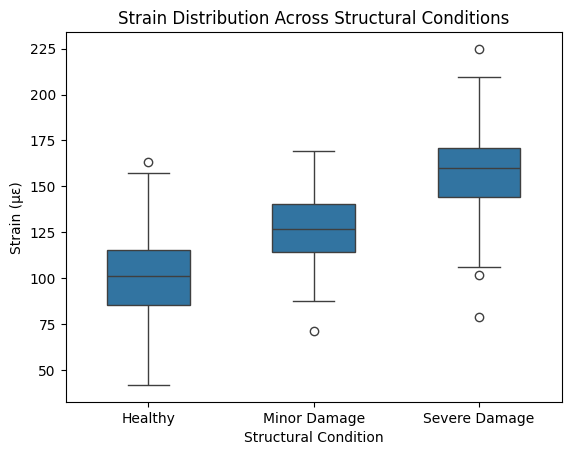

In [38]:
sns.boxplot(
    data=df,
    x="Condition Label",
    y="Strain (με)",
    width=.5
)

plt.xticks(
    [0, 1, 2],
    ["Healthy", "Minor Damage", "Severe Damage"]
)

plt.xlabel("Structural Condition")
plt.ylabel("Strain (µε)")
plt.title("Strain Distribution Across Structural Conditions")
plt.show()

In [39]:
df.groupby("Condition Label")["Strain (με)"].describe()

,count,mean,std,min,25%,50%,75%,max
Condition Label,,,,,,,,
0,704.0,100.600483,21.120730,41.860236,85.433609,101.009693,115.166661,163.041135
1,183.0,126.645325,18.408386,71.411026,114.286580,126.543965,140.443932,169.065183
2,113.0,158.347301,23.848050,78.979840,144.001190,159.859100,171.034816,224.861859
